# Movie Theatre & Ticket Booking Analytics — Part A (Matplotlib)
**Course:** Data Analytics (CAUE603) &nbsp;|&nbsp; **Branch:** MCA &nbsp;|&nbsp; **Semester:** III

This notebook answers Questions 1–15 using **Python, Pandas and Matplotlib** on the
`Movies`, `Shows` and `Bookings` tables described in the assignment.

> **Note on data:** The instructor's actual CSV files were not attached to this notebook, so a
> synthetic dataset (`Movies.csv`, `Shows.csv`, `Bookings.csv`) with the **exact same column
> names and relationships** described in the problem statement was generated in Cell 2 below.
> If you have the real files from your instructor, just place them in the same folder as this
> notebook (or update the paths in Cell 3) — every question below will run unchanged because
> only the column names matter, not where the data came from.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

## Data Setup
The cell below (re)creates `Movies.csv`, `Shows.csv` and `Bookings.csv` **only if they don't
already exist** in the working folder — so if you drop in the real instructor files with the
same names, this cell will *not* overwrite them.

In [2]:
movies = pd.read_csv('Movies.csv', parse_dates=['Release_Date'])
shows = pd.read_csv('Shows.csv', parse_dates=['Show_Date'])
bookings = pd.read_csv('Bookings.csv', parse_dates=['Booking_Date'])

print('Movies :', movies.shape)
print('Shows  :', shows.shape)
print('Bookings:', bookings.shape)

Movies : (40, 9)
Shows  : (3630, 11)
Bookings: (36274, 13)


## Q1. Dataset Exploration
Load the three datasets and perform basic exploratory analysis — number of movies, shows,
bookings, customers, genres, cities, payment modes and booking channels.

In [3]:
print('--- Basic Shape ---')
print(f"Movies table   : {movies.shape[0]} rows, {movies.shape[1]} columns")
print(f"Shows table    : {shows.shape[0]} rows, {shows.shape[1]} columns")
print(f"Bookings table : {bookings.shape[0]} rows, {bookings.shape[1]} columns")

print('\n--- Key Counts ---')
print(f"Number of unique movies          : {movies['Movie_ID'].nunique()}")
print(f"Number of shows                  : {shows['Show_ID'].nunique()}")
print(f"Number of bookings               : {bookings['Booking_ID'].nunique()}")
print(f"Number of unique customers       : {bookings['Customer_ID'].nunique()}")
print(f"Number of genres                 : {movies['Genre'].nunique()} -> {sorted(movies['Genre'].unique())}")
print(f"Number of cities                 : {shows['City'].nunique()} -> {sorted(shows['City'].unique())}")
print(f"Number of payment modes          : {bookings['Payment_Mode'].nunique()} -> {sorted(bookings['Payment_Mode'].unique())}")
print(f"Number of booking channels       : {bookings['Booking_Channel'].nunique()} -> {sorted(bookings['Booking_Channel'].unique())}")

print('\n--- Missing Values ---')
print(pd.concat([movies.isna().sum(), shows.isna().sum(), bookings.isna().sum()],
                keys=['Movies','Shows','Bookings']))

--- Basic Shape ---
Movies table   : 40 rows, 9 columns
Shows table    : 3630 rows, 11 columns
Bookings table : 36274 rows, 13 columns

--- Key Counts ---
Number of unique movies          : 40
Number of shows                  : 3630
Number of bookings               : 36274
Number of unique customers       : 1800
Number of genres                 : 10 -> ['Action', 'Animation', 'Comedy', 'Drama', 'Fantasy', 'Horror', 'Musical', 'Romance', 'Sci-Fi', 'Thriller']
Number of cities                 : 8 -> ['Ahmedabad', 'Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai', 'Pune']
Number of payment modes          : 4 -> ['Card', 'Cash', 'UPI', 'Wallet']
Number of booking channels       : 3 -> ['App', 'Counter', 'Website']

--- Missing Values ---
Movies    Movie_ID             0
          Movie_Name           0
          Genre                0
          Language             0
          Certificate          0
          Duration_Min         0
          Release_Date         0
         

## Q2. Movie Genre Analysis
Bar chart of the number of movies in each genre.

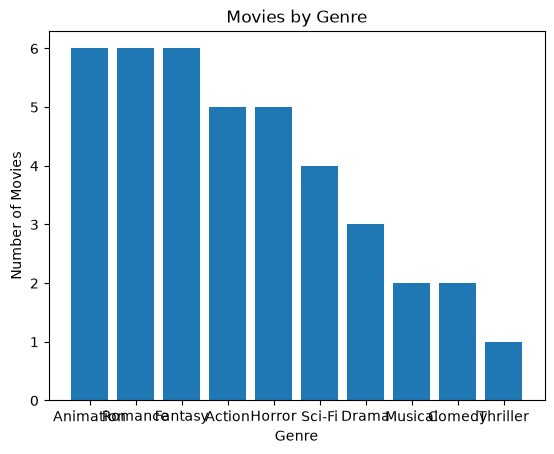

Most Common Genre: Animation
Total Movies: 6


In [4]:
genre_counts = movies['Genre'].value_counts()

plt.bar(genre_counts.index, genre_counts.values)

plt.title("Movies by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")

plt.show()

print("Most Common Genre:", genre_counts.idxmax())
print("Total Movies:", genre_counts.max())

## Q3. Movie Language Analysis
Distribution of movies by language (pie chart, since language is a categorical share of a
whole catalogue).

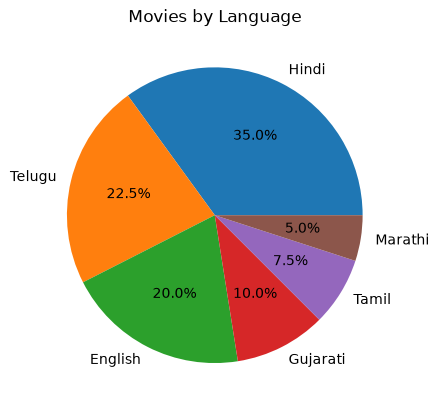

Most Common Language: Hindi
Total Movies: 14


In [5]:
lang_counts = movies['Language'].value_counts()

plt.pie(lang_counts.values, labels=lang_counts.index, autopct='%1.1f%%')

plt.title("Movies by Language")
plt.show()

print("Most Common Language:", lang_counts.idxmax())
print("Total Movies:", lang_counts.max())

## Q4. Show Trend Analysis
Line chart of the number of shows conducted over time (daily).

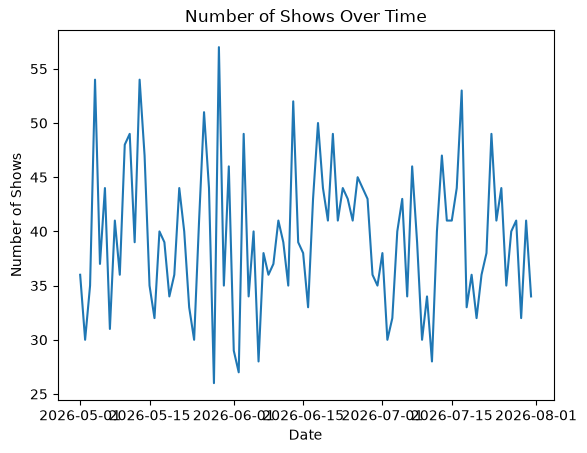

Highest Shows: 57
Lowest Shows: 26


In [6]:
shows_per_day = shows.groupby(shows['Show_Date'].dt.date).size()

plt.plot(shows_per_day.index, shows_per_day.values)

plt.title("Number of Shows Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Shows")

plt.show()

print("Highest Shows:", shows_per_day.max())
print("Lowest Shows:", shows_per_day.min())

## Q5. Booking Trend Analysis
Line chart of confirmed bookings over time.

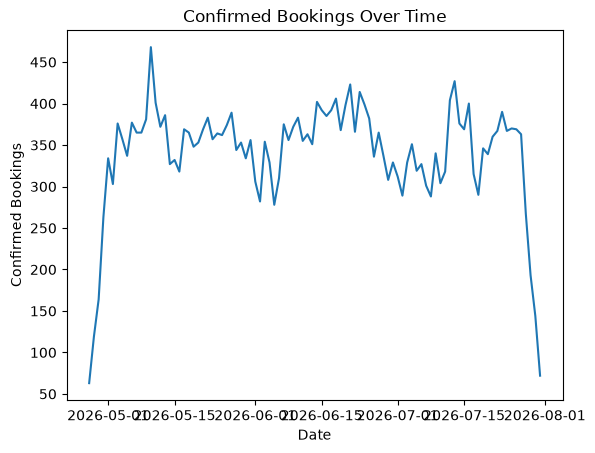

Highest Bookings: 468
Lowest Bookings: 63
Average Bookings: 340.1041666666667


In [7]:
confirmed = bookings[bookings['Booking_Status'] == 'Confirmed']

bookings_per_day = confirmed.groupby(
    confirmed['Booking_Date'].dt.date
).size()

plt.plot(bookings_per_day.index, bookings_per_day.values)

plt.title("Confirmed Bookings Over Time")
plt.xlabel("Date")
plt.ylabel("Confirmed Bookings")

plt.show()

print("Highest Bookings:", bookings_per_day.max())
print("Lowest Bookings:", bookings_per_day.min())
print("Average Bookings:", bookings_per_day.mean())

## Q6. Revenue by Movie
Join Bookings → Shows → Movies to get total revenue per movie, then plot the Top 10.

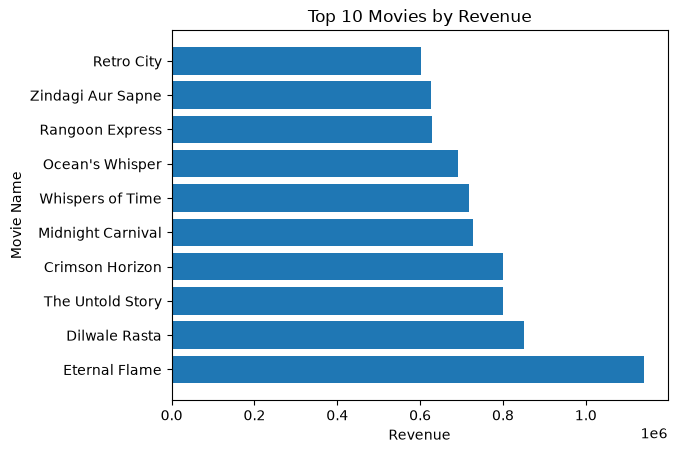

Movie_Name
Eternal Flame        1140490.78
Dilwale Rasta         851926.61
The Untold Story      798891.12
Crimson Horizon       798879.46
Midnight Carnival     728218.95
Whispers of Time      718087.71
Ocean's Whisper       690348.37
Rangoon Express       627829.11
Zindagi Aur Sapne     625396.05
Retro City            602445.78
Name: Final_Amount, dtype: float64


In [8]:
bk_show = confirmed.merge(shows, on='Show_ID')

bk_movie = bk_show.merge(movies, on='Movie_ID')

revenue = bk_movie.groupby('Movie_Name')['Final_Amount'].sum()

top10 = revenue.sort_values(ascending=False).head(10)

plt.barh(top10.index, top10.values)

plt.title("Top 10 Movies by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Movie Name")

plt.show()

print(top10)



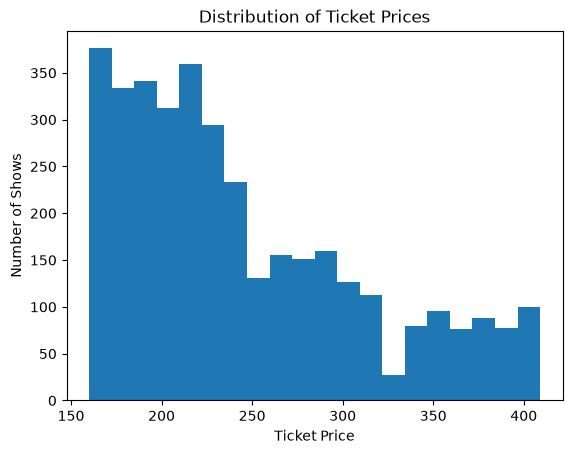

In [10]:
plt.hist(shows['Ticket_Price'], bins=20)

plt.title("Distribution of Ticket Prices")
plt.xlabel("Ticket Price")
plt.ylabel("Number of Shows")

plt.show()


## Q11. Ticket Price vs Revenue
Scatter plot: base ticket price of a show vs. total revenue that show generated.

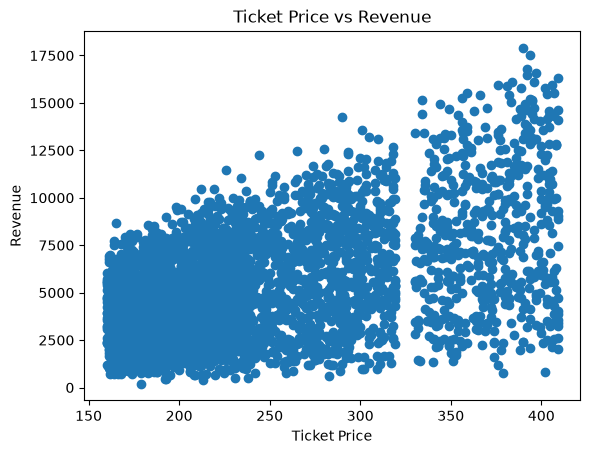

Correlation: 0.47926510700439107


In [11]:
show_revenue = confirmed.groupby('Show_ID')['Final_Amount'].sum()

price_rev = shows[['Show_ID', 'Ticket_Price']].copy()

price_rev['Revenue'] = price_rev['Show_ID'].map(show_revenue).fillna(0)

plt.scatter(price_rev['Ticket_Price'], price_rev['Revenue'])

plt.title("Ticket Price vs Revenue")
plt.xlabel("Ticket Price")
plt.ylabel("Revenue")

plt.show()

corr = price_rev['Ticket_Price'].corr(price_rev['Revenue'])

print("Correlation:", corr)